# Detailed evaluation — reader ← GNN

Reads `evaluated_result_detailed.csv`, written by `src/evaluation/evaluate_detailed.py`.
Every metric is described in `docs/detailed_evaluation.md`. The last section compares this arm
paper by paper with another arm's detailed CSV, if one exists.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

ARM = 'reader ← GNN'
df = pd.read_csv('evaluated_result_detailed.csv')

NUMERIC = ['rouge1_f', 'rouge2_f', 'rougeL_f', 'bertscore_p', 'bertscore_r', 'bertscore_f1',
           'llm_coherence', 'llm_language',
           'field_match', 'contribution_match', 'modality_jaccard', 'method_family_match',
           'subfield', 'problem', 'task',
           'claims_total', 'claims_supported', 'claims_contradicted', 'claim_precision',
           'id_rank', 'id_correct', 'pair_score',
           'tfidf_rank', 'ontarget_gold_sim', 'ontarget_max_ref_sim', 'ontarget_margin']
NUMERIC = [c for c in NUMERIC if c in df.columns]   # pair_score only exists with --against
for col in NUMERIC:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['tfidf_top1'] = (df['tfidf_rank'] == 1).astype(float)

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows')
df.head(3)

945 rows


,node_id,mag_id,original_abstract,generated_abstract,num_of_neighbors,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,...,claims_supported,claims_contradicted,claim_precision,llm_coherence,llm_language,id_rank,id_correct,id_options,tfidf_top1,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a new method for training deep neur...,69,0.2500,0.0709,0.1406,0.8603,0.8124,...,0,3,0.00,7,8,1,1.0,160912|88972|1564|5100,0.0,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,"In this paper, we propose a novel deep learnin...",50,0.3779,0.1204,0.2120,0.8646,0.8406,...,2,4,0.25,6,7,1,1.0,145426|169088|127541|39733,1.0,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We present a new approach to the specification...,37,0.3401,0.0735,0.1862,0.8410,0.8604,...,0,6,0.00,8,8,3,0.0,152273|184353|213866|202507,0.0,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

def dist_plot(col: str, values: list, title: str, xlabel: str, color: str):
    """Count of papers per score value."""
    counts = df[col].dropna().round().astype(int).value_counts().reindex(values, fill_value=0)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.bar([str(v) for v in values], counts.values, color=color, edgecolor='white', linewidth=0.6)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                str(int(v)), ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Number of abstracts')
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()
    return counts

## Summary: every metric

In [3]:
summary = pd.DataFrame({
    'mean': df[NUMERIC + ['tfidf_top1']].mean(),
    'median': df[NUMERIC + ['tfidf_top1']].median(),
    'n': df[NUMERIC + ['tfidf_top1']].notna().sum(),
}).round(3)
summary

,mean,median,n
rouge1_f,0.318,0.321,945
rouge2_f,0.062,0.058,945
rougeL_f,0.175,0.174,945
bertscore_p,0.858,0.860,945
bertscore_r,0.831,0.831,945
bertscore_f1,0.844,0.846,945
llm_coherence,7.361,8.000,945
llm_language,7.893,8.000,945
field_match,0.773,1.000,939
contribution_match,0.691,1.000,945


## Kept from the current evaluator

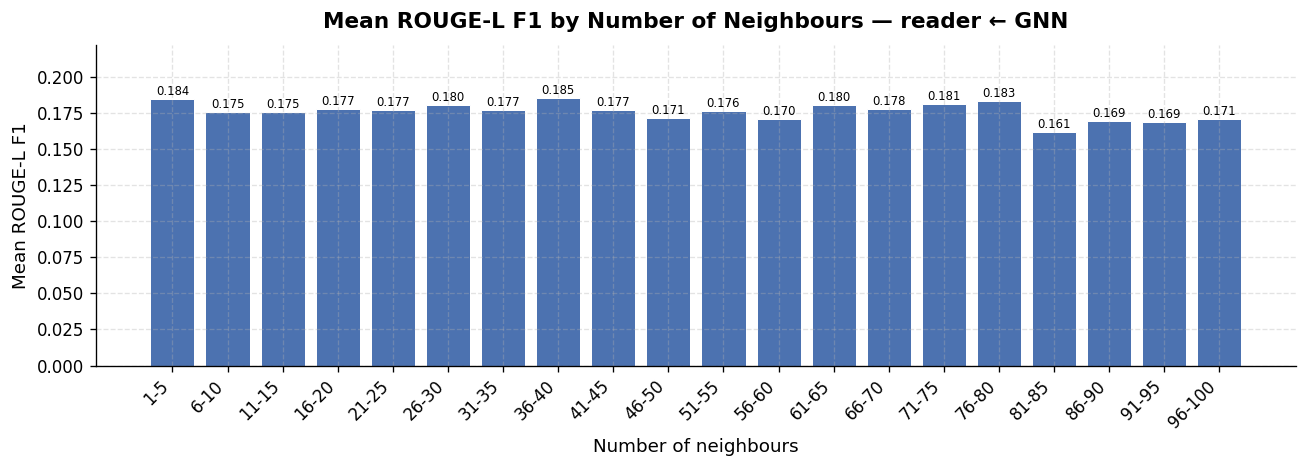

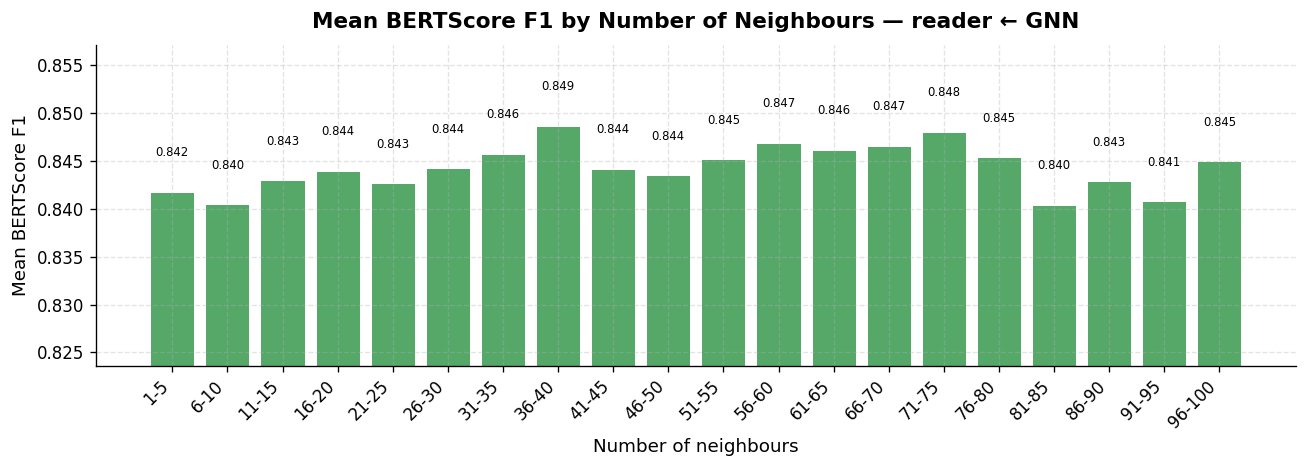

In [4]:
# ── ROUGE-L and BERTScore by neighbours ──────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean, title=f'Mean ROUGE-L F1 by Number of Neighbours — {ARM}',
         ylabel='Mean ROUGE-L F1', color='#4C72B0', ylim=(0, max(rougel_mean.dropna()) * 1.2))

bert_mean = weighted_group_mean(df, 'bertscore_f1')
bar_plot(bert_mean, title=f'Mean BERTScore F1 by Number of Neighbours — {ARM}',
         ylabel='Mean BERTScore F1', color='#55A868',
         ylim=(bert_mean.dropna().min() * 0.98, bert_mean.dropna().max() * 1.01))

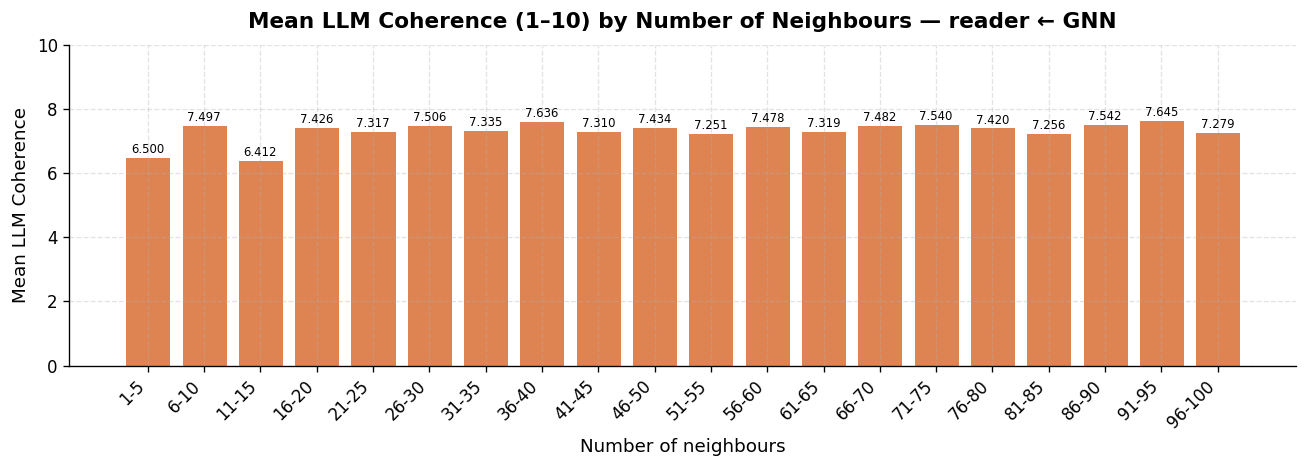

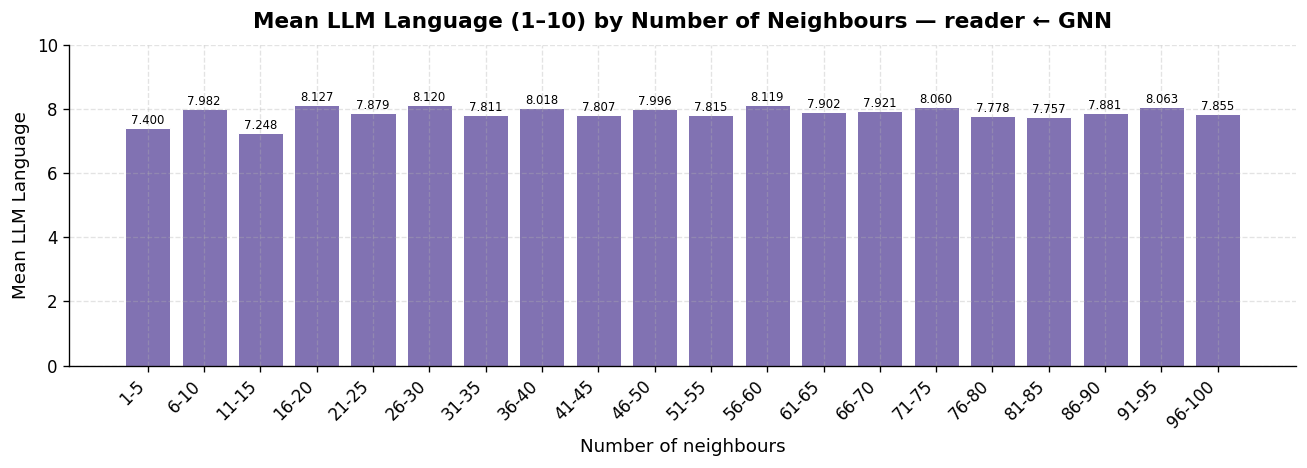

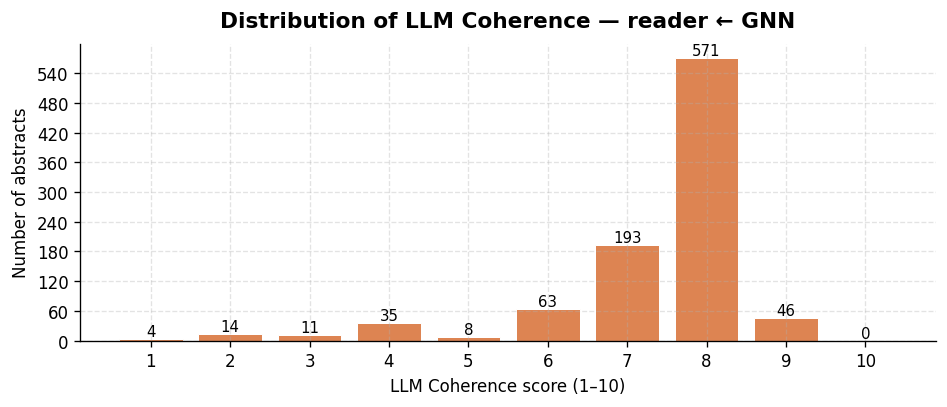

llm_coherence
1       4
2      14
3      11
4      35
5       8
6      63
7     193
8     571
9      46
10      0
Name: count, dtype: int64

In [5]:
# ── Coherence and language ───────────────────────────────────────────────────
bar_plot(weighted_group_mean(df, 'llm_coherence'),
         title=f'Mean LLM Coherence (1–10) by Number of Neighbours — {ARM}',
         ylabel='Mean LLM Coherence', color='#DD8452', ylim=(0, 10))
bar_plot(weighted_group_mean(df, 'llm_language'),
         title=f'Mean LLM Language (1–10) by Number of Neighbours — {ARM}',
         ylabel='Mean LLM Language', color='#8172B2', ylim=(0, 10))
dist_plot('llm_coherence', list(range(1, 11)), f'Distribution of LLM Coherence — {ARM}',
          'LLM Coherence score (1–10)', '#DD8452')

## A. Blind facets

Each abstract is labelled on its own from fixed lists; the score is whether the generated
label matches the gold label. Field is expected near the ceiling for every arm.

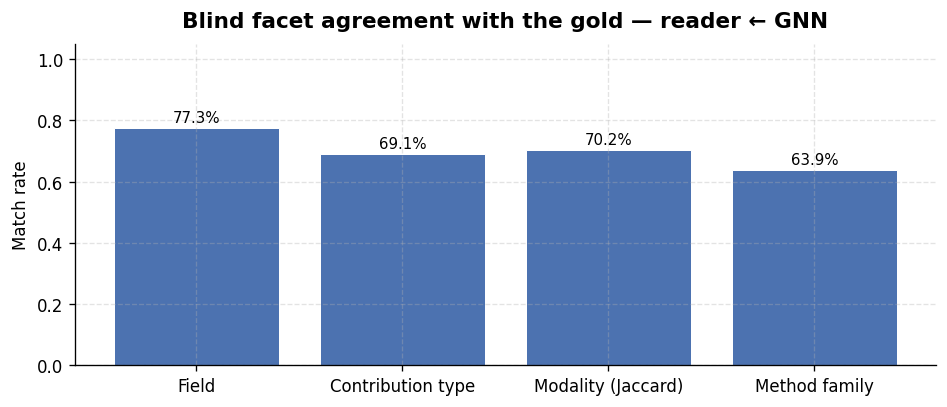

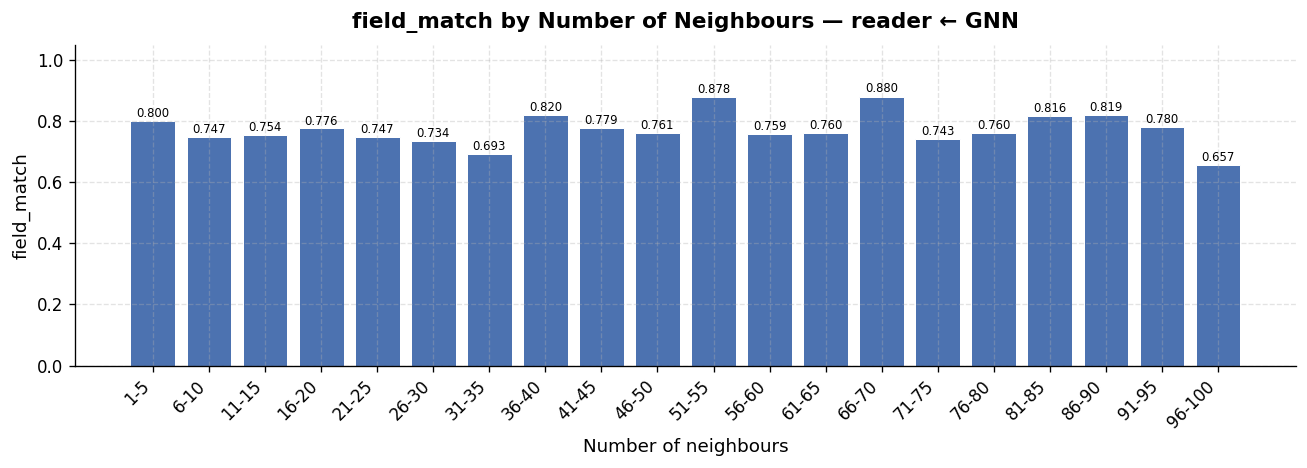

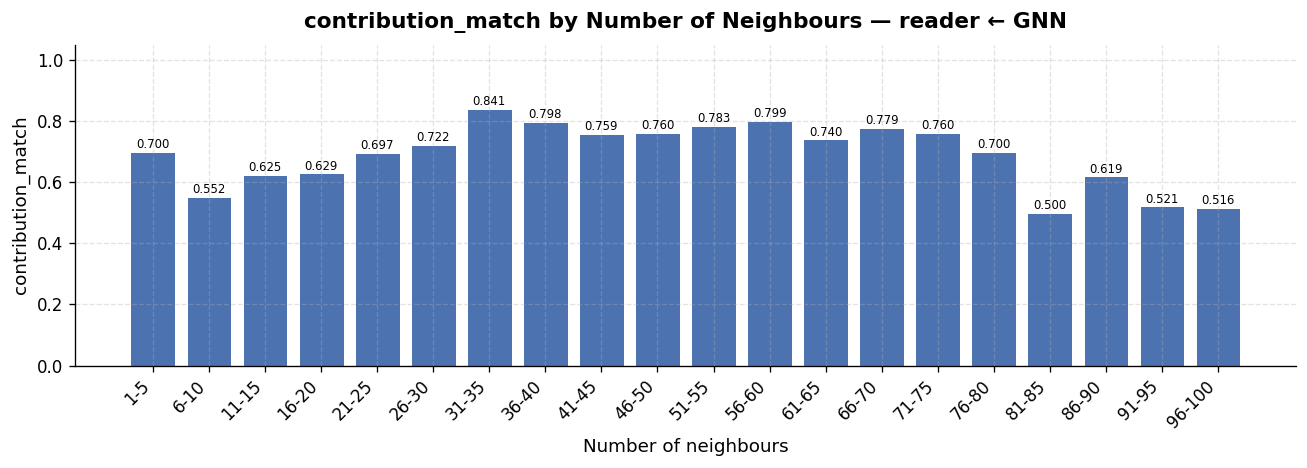

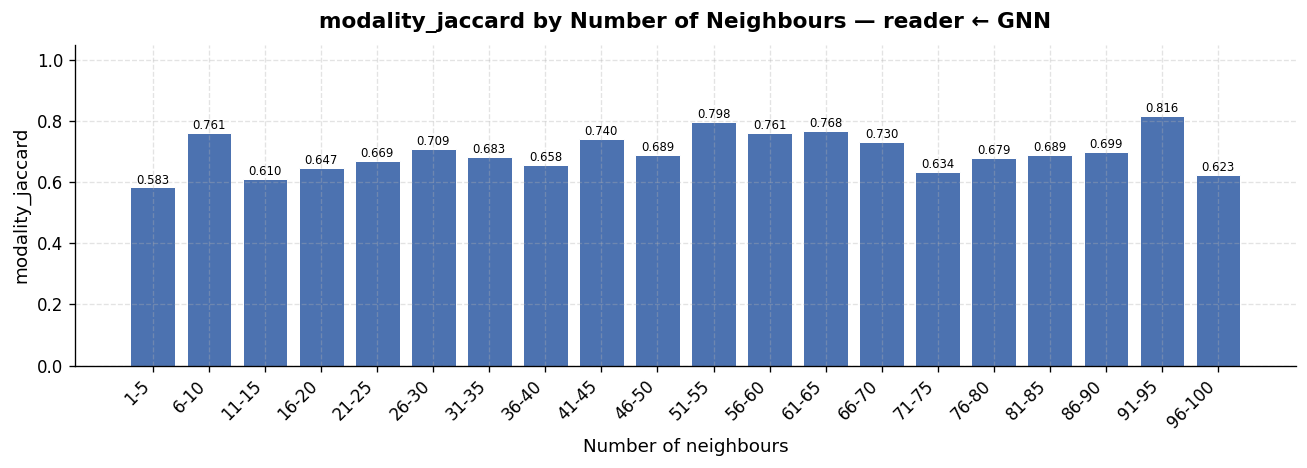

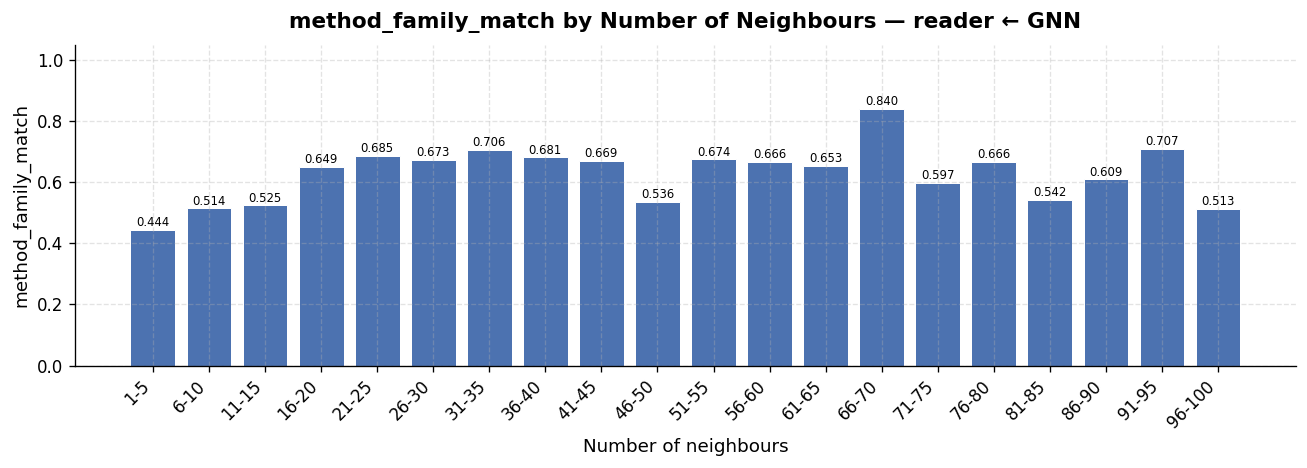

In [6]:
FACETS = ['field_match', 'contribution_match', 'modality_jaccard', 'method_family_match']
FACET_LABELS = ['Field', 'Contribution type', 'Modality (Jaccard)', 'Method family']
rates = df[FACETS].mean().values

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(FACET_LABELS, rates, color='#4C72B0', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.1%}', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Match rate')
ax.set_title(f'Blind facet agreement with the gold — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

for col in FACETS:
    bar_plot(weighted_group_mean(df, col), title=f'{col} by Number of Neighbours — {ARM}',
             ylabel=col, color='#4C72B0', ylim=(0, 1.05))

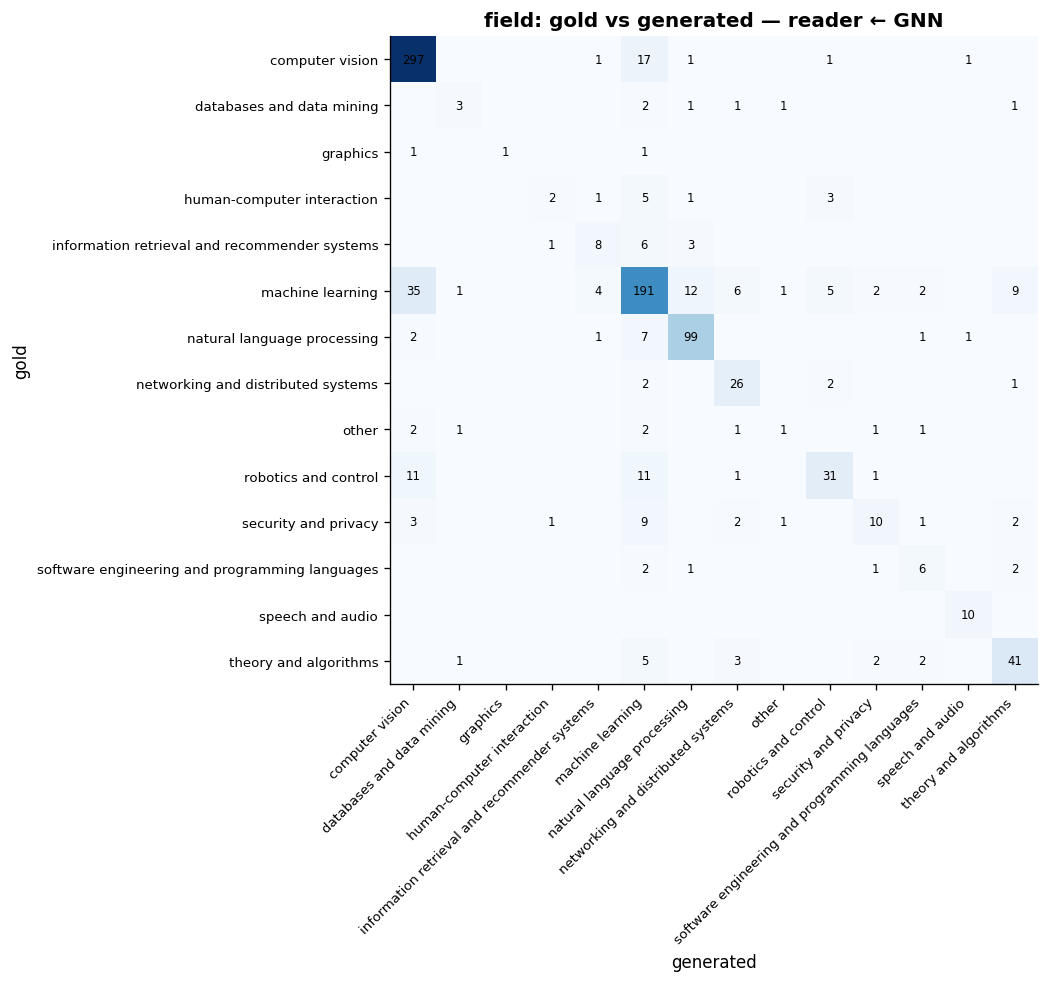

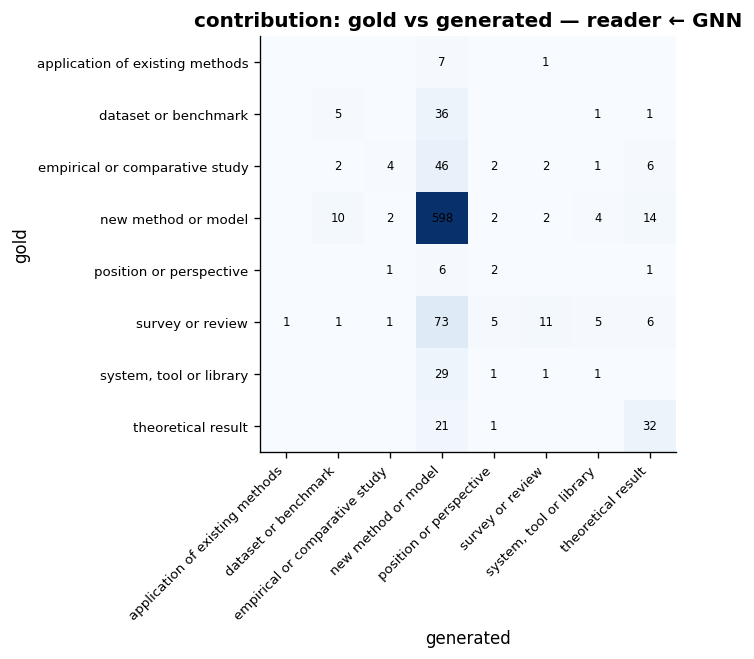

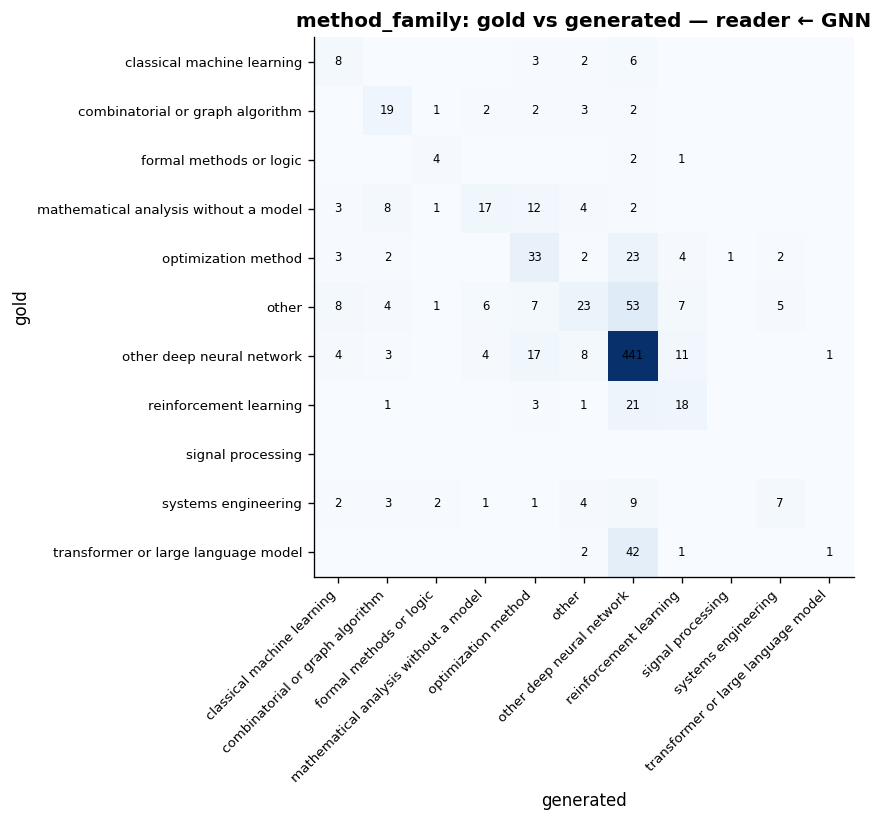

In [7]:
# ── Confusion tables: gold label (rows) vs generated label (columns) ─────────
def confusion(facet: str):
    table = pd.crosstab(df[f'gold_{facet}'], df[f'gen_{facet}'])
    labels = sorted(set(table.index) | set(table.columns))
    table = table.reindex(index=labels, columns=labels, fill_value=0)
    fig, ax = plt.subplots(figsize=(0.55 * len(labels) + 3, 0.45 * len(labels) + 2))
    ax.imshow(table.values, cmap='Blues')
    ax.grid(False)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if table.values[i, j]:
                ax.text(j, i, table.values[i, j], ha='center', va='center', fontsize=7)
    ax.set_xlabel('generated')
    ax.set_ylabel('gold')
    ax.set_title(f'{facet}: gold vs generated — {ARM}', fontsize=12, fontweight='bold')
    fig.tight_layout()
    plt.show()

for facet in ['field', 'contribution', 'method_family']:
    confusion(facet)

## B. Comparison with the gold

Subfield, problem and task on the anchored 0–3 scale (0 different, 1 related, 2 same with
differences in detail, 3 same).

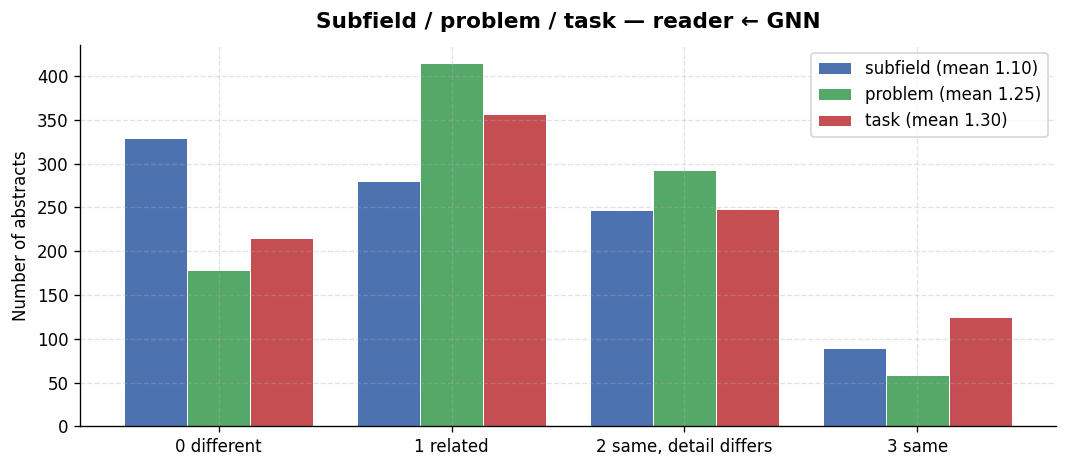

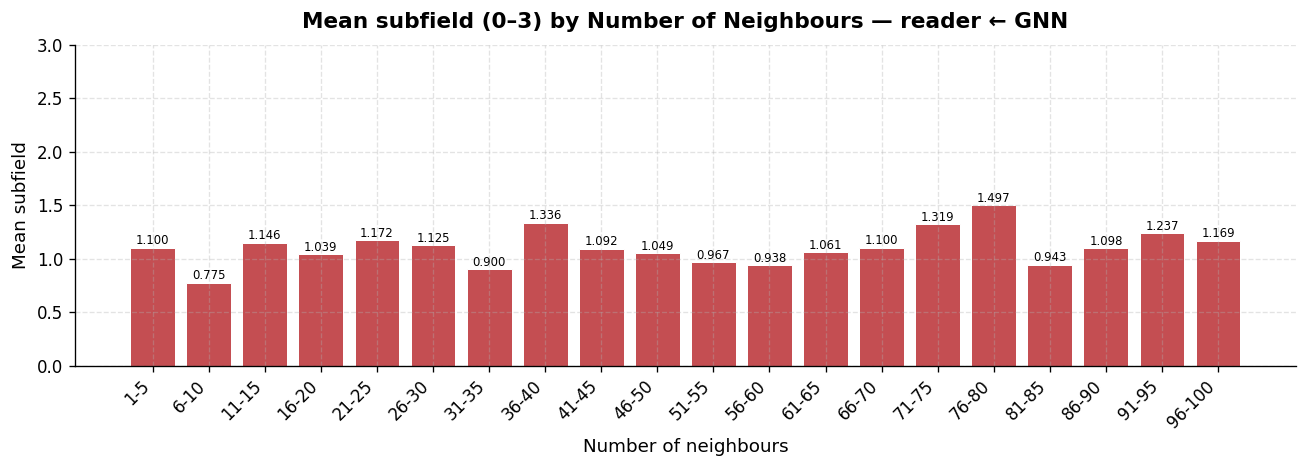

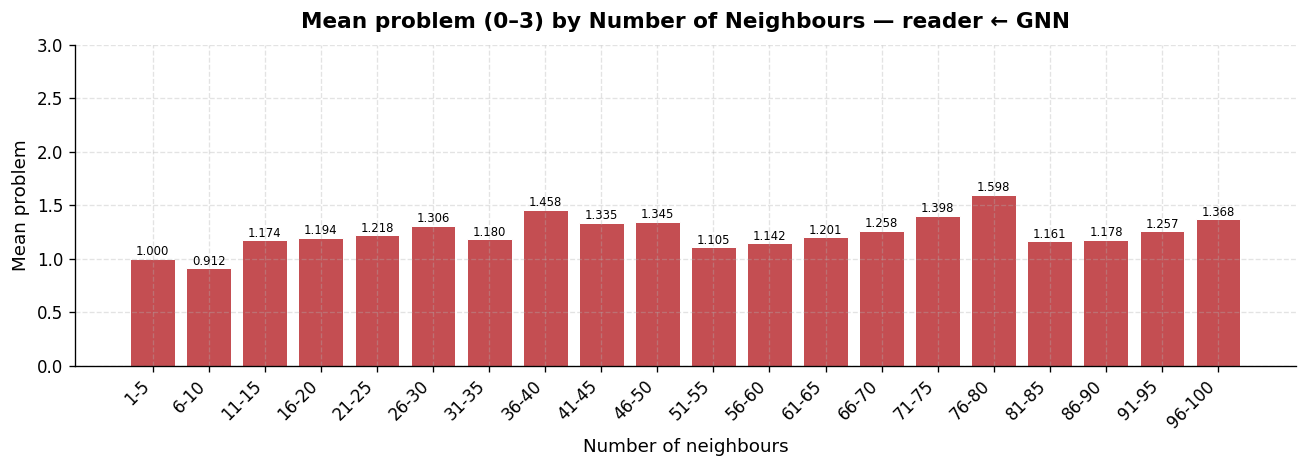

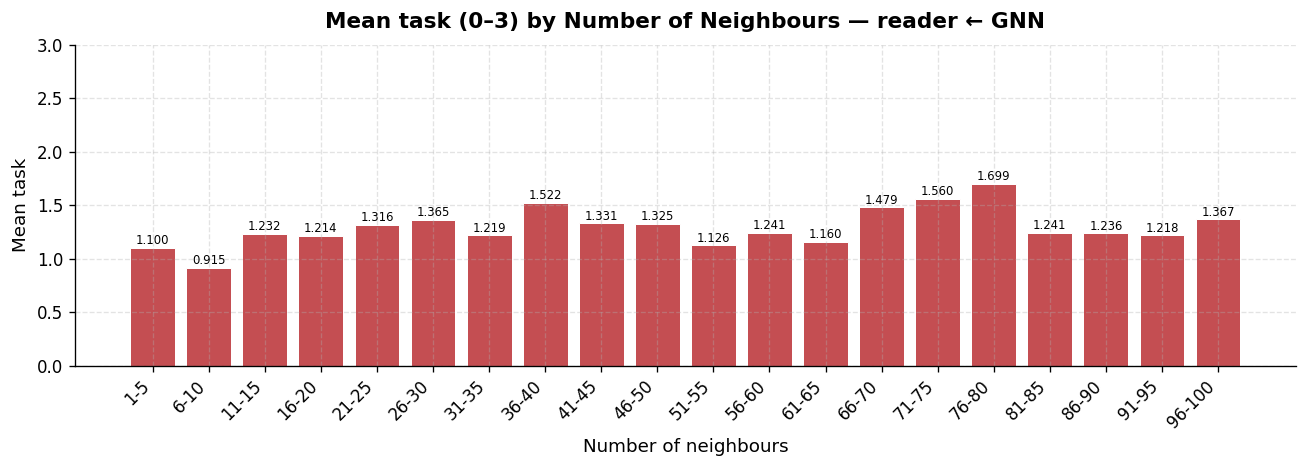

,subfield,problem,task
0,329,178,215
1,280,415,357
2,247,293,248
3,89,59,125


In [8]:
SCALE = ['subfield', 'problem', 'task']
counts = pd.DataFrame({c: df[c].dropna().round().astype(int).value_counts().reindex(range(4), fill_value=0)
                       for c in SCALE})

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(4)
for k, (c, color) in enumerate(zip(SCALE, ['#4C72B0', '#55A868', '#C44E52'])):
    ax.bar(x + (k - 1) * 0.27, counts[c].values, width=0.27, label=f'{c} (mean {df[c].mean():.2f})',
           color=color, edgecolor='white', linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels(['0 different', '1 related', '2 same, detail differs', '3 same'])
ax.set_ylabel('Number of abstracts')
ax.set_title(f'Subfield / problem / task — {ARM}', fontsize=13, fontweight='bold', pad=10)
ax.legend()
fig.tight_layout()
plt.show()

for c in SCALE:
    bar_plot(weighted_group_mean(df, c), title=f'Mean {c} (0–3) by Number of Neighbours — {ARM}',
             ylabel=f'Mean {c}', color='#C44E52', ylim=(0, 3))
counts

claims per abstract:        5.42
supported per abstract:     0.64
contradicted per abstract:  2.26
claim precision (mean):     0.117
pooled precision:           0.118
abstracts with ≥1 contradiction: 71.6%
abstracts with no claims:   0.6%


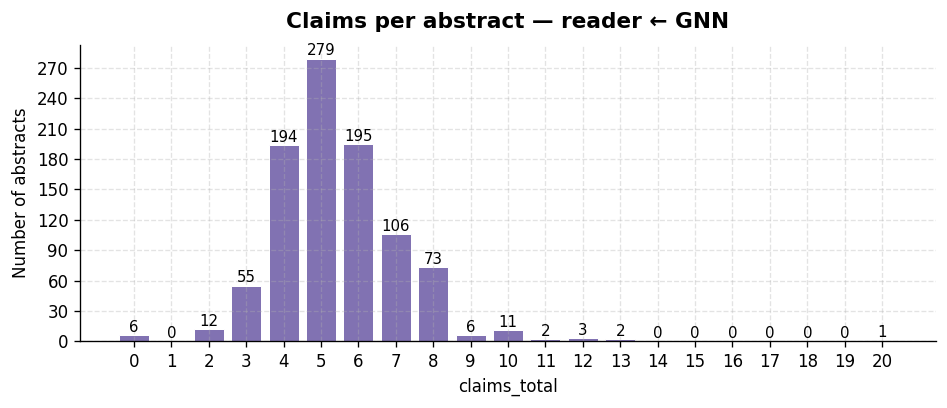

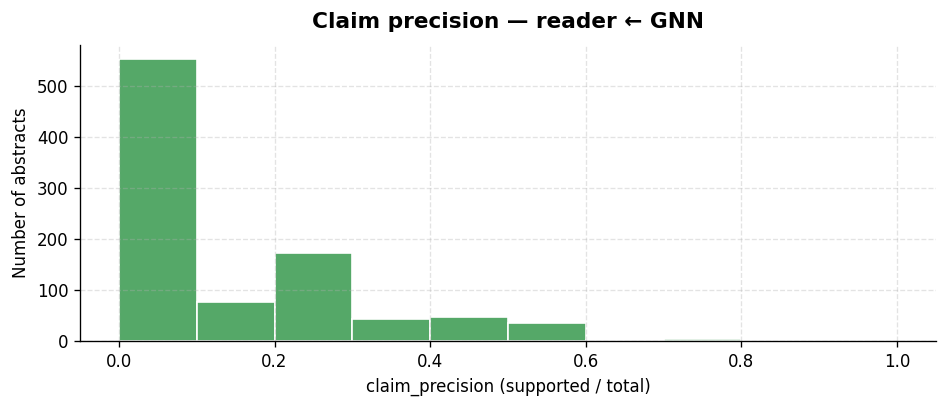

In [9]:
# ── Claims: specificity, precision, contradictions ───────────────────────────
print(f"claims per abstract:        {df['claims_total'].mean():.2f}")
print(f"supported per abstract:     {df['claims_supported'].mean():.2f}")
print(f"contradicted per abstract:  {df['claims_contradicted'].mean():.2f}")
print(f"claim precision (mean):     {df['claim_precision'].mean():.3f}")
print(f"pooled precision:           {df['claims_supported'].sum() / df['claims_total'].sum():.3f}")
print(f"abstracts with ≥1 contradiction: {(df['claims_contradicted'] > 0).mean():.1%}")
print(f"abstracts with no claims:   {(df['claims_total'] == 0).mean():.1%}")

max_claims = int(df['claims_total'].max())
dist_plot('claims_total', list(range(0, max_claims + 1)), f'Claims per abstract — {ARM}',
          'claims_total', '#8172B2')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df['claim_precision'].dropna(), bins=np.linspace(0, 1, 11), color='#55A868', edgecolor='white')
ax.set_xlabel('claim_precision (supported / total)')
ax.set_ylabel('Number of abstracts')
ax.set_title(f'Claim precision — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

## C. Identification among hard distractors

The judge ranks the gold and its four nearest papers (never its own references). Chance is
20% correct and a mean rank of 3.

id correct (top-1): 24.6%   (chance 20%)
mean id rank:       2.69   (chance 3.00)
id MRR:             0.505   (chance 0.457)


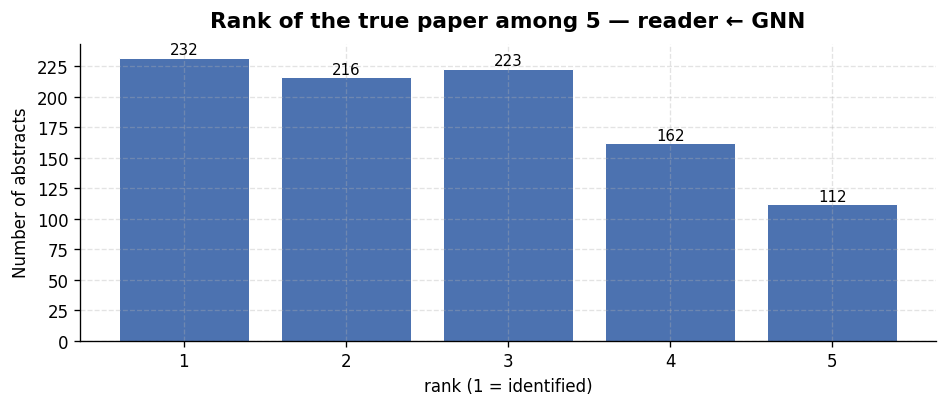

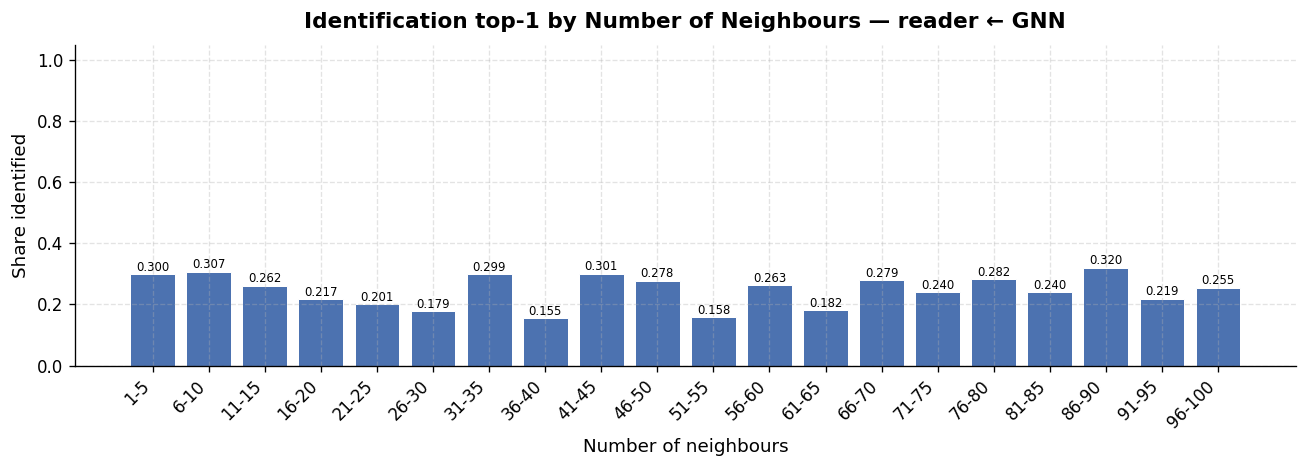

In [10]:
print(f"id correct (top-1): {df['id_correct'].mean():.1%}   (chance 20%)")
print(f"mean id rank:       {df['id_rank'].mean():.2f}   (chance 3.00)")
print(f"id MRR:             {(1 / df['id_rank']).mean():.3f}   (chance 0.457)")

counts = dist_plot('id_rank', [1, 2, 3, 4, 5], f'Rank of the true paper among 5 — {ARM}',
                   'rank (1 = identified)', '#4C72B0')
bar_plot(weighted_group_mean(df, 'id_correct'),
         title=f'Identification top-1 by Number of Neighbours — {ARM}',
         ylabel='Share identified', color='#4C72B0', ylim=(0, 1.05))

## No judge: TF-IDF identifiability and on-target margin

TF-IDF top-1 (among all 945 golds): 16.5%
TF-IDF MRR:                         0.271
on-target margin (mean):            -0.130
closer to a reference than to gold: 96.0%


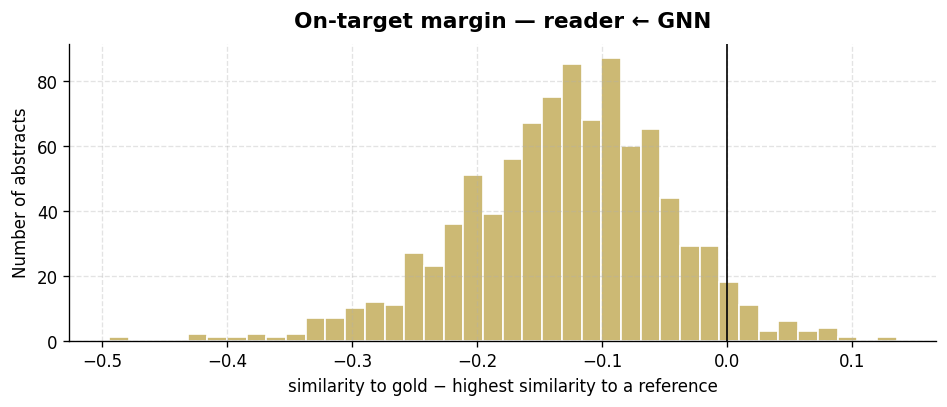

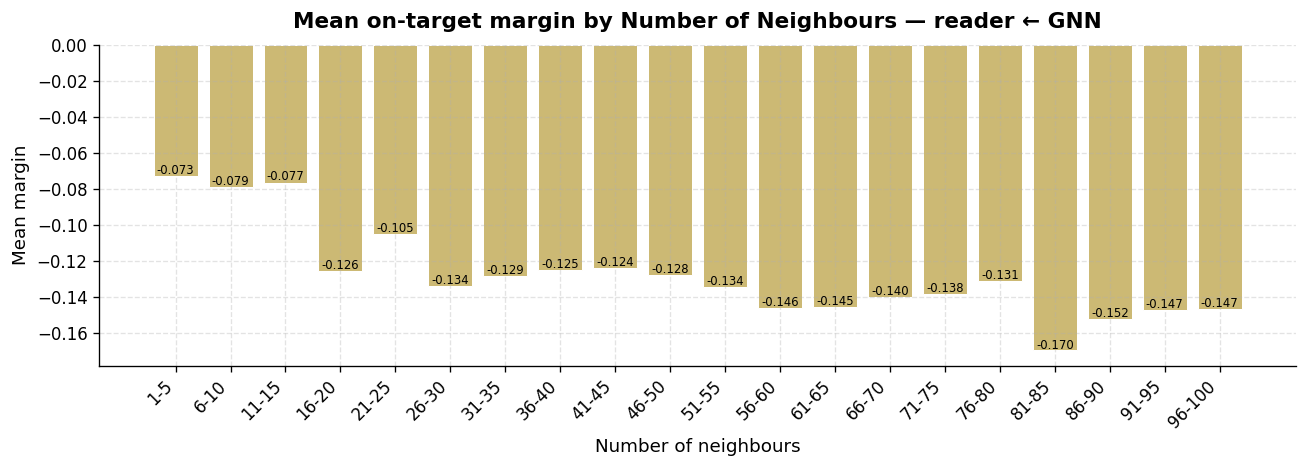

In [11]:
print(f"TF-IDF top-1 (among all {len(df)} golds): {df['tfidf_top1'].mean():.1%}")
print(f"TF-IDF MRR:                         {(1 / df['tfidf_rank']).mean():.3f}")
print(f"on-target margin (mean):            {df['ontarget_margin'].mean():.3f}")
print(f"closer to a reference than to gold: {(df['ontarget_margin'] < 0).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df['ontarget_margin'].dropna(), bins=40, color='#CCB974', edgecolor='white')
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('similarity to gold − highest similarity to a reference')
ax.set_ylabel('Number of abstracts')
ax.set_title(f'On-target margin — {ARM}', fontsize=13, fontweight='bold', pad=10)
fig.tight_layout()
plt.show()

bar_plot(weighted_group_mean(df, 'ontarget_margin'),
         title=f'Mean on-target margin by Number of Neighbours — {ARM}',
         ylabel='Mean margin', color='#CCB974')

## D. Pairwise preference

Only present when the CSV was scored with `--against`. 1 = this arm judged better in both
orders, 0.5 = split or tie, 0 = worse in both.

In [12]:
if 'pair_score' in df.columns:
    p = df['pair_score'].dropna()
    se = p.std() / np.sqrt(len(p))
    print(f"pair score: {p.mean():.3f} ± {se:.3f} (SE)   0.5 = no preference")
    print(f"wins both orders: {(p == 1).mean():.1%}   split/tie: {(p == 0.5).mean():.1%}   "
          f"loses both: {(p == 0).mean():.1%}")
    counts = p.value_counts().reindex([0.0, 0.25, 0.5, 0.75, 1.0], fill_value=0)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar([str(v) for v in counts.index], counts.values, color='#937860', edgecolor='white')
    ax.set_xlabel('pair_score')
    ax.set_ylabel('Number of abstracts')
    ax.set_title(f'Pairwise preference — {ARM}', fontsize=13, fontweight='bold', pad=10)
    fig.tight_layout()
    plt.show()
    bar_plot(weighted_group_mean(df, 'pair_score'),
             title=f'Pair score by Number of Neighbours — {ARM}',
             ylabel='Mean pair score', color='#937860', ylim=(0, 1.05))
else:
    print('no pair_score column: this CSV was scored without --against')

no pair_score column: this CSV was scored without --against


## Examples

In [13]:
pd.set_option('display.max_colwidth', 2000)
SHOW = ['node_id', 'original_abstract', 'generated_abstract']

# 2 examples per task score
(df[df['task'].notna()].sort_values('task').groupby('task', sort=True)
   .apply(lambda g: g.head(2)).reset_index(drop=True)[SHOW + ['subfield', 'problem', 'task']])

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_45667/3392447683.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2)).reset_index(drop=True)[SHOW + ['subfield', 'problem', 'task']])


,node_id,original_abstract,generated_abstract,subfield,problem,task
0,1089,"We deal with the \textit{selective classification} problem (supervised-learning problem with a rejection option), where we want to achieve the best performance at a certain level of coverage of the data. We transform the original $m$-class classification problem to $(m+1)$-class where the $(m+1)$-th class represents the model abstaining from making a prediction due to uncertainty. Inspired by portfolio theory, we propose a loss function for the selective classification problem based on the doubling rate of gambling. We show that minimizing this loss function has a natural interpretation as maximizing the return of a \textit{horse race}, where a player aims to balance between betting on an outcome (making a prediction) when confident and reserving one's winnings (abstaining) when not confident. This loss function allows us to train neural networks and characterize the uncertainty of prediction in an end-to-end fashion. In comparison with previous methods, our method requires almost no modification to the model inference algorithm or neural architecture. Experimentally, we show that our method can identify both uncertain and outlier data points, and achieves strong results on SVHN and CIFAR10 at various coverages of the data.","We propose a new method for training deep neural networks that is based on the idea of using a small number of training samples to estimate the gradient of the loss function. The method is called the ""stochastic gradient descent with randomization"" (SGDR) and it is shown that it can be used to train deep neural networks with a high accuracy.",0,0,0
1,77947,"Modeling relations between languages can offer understanding of language characteristics and uncover similarities and differences between languages. Automated methods applied to large textual corpora can be seen as opportunities for novel statistical studies of language development over time, as well as for improving cross-lingual natural language processing techniques. In this work, we first propose how to represent textual data as a directed, weighted network by the text2net algorithm. We next explore how various fast, network-topological metrics, such as network community structure, can be used for cross-lingual comparisons. In our experiments, we employ eight different network topology metrics, and empirically showcase on a parallel corpus, how the methods can be used for modeling the relations between nine selected languages. We demonstrate that the proposed method scales to large corpora consisting of hundreds of thousands of aligned sentences on an of-the-shelf laptop. We observe that on the one hand properties such as communities, capture some of the known differences between the languages, while others can be seen as novel opportunities for linguistic studies.","The emergence of social media has created a new paradigm for the study of human behavior. The ability to collect and analyze large-scale social media data has enabled researchers to study human behavior at an unprecedented scale. In this paper, we present a survey of the state-of-the-art in social media analysis. We focus on the analysis of social media data from a network science perspective. We review the most important research areas in social media analysis, including social network analysis, community detection, link prediction, and information diffusion. We also review the most important research challenges in social media analysis, such as the analysis of multilayer networks, the analysis of temporal networks, and the analysis of networks with heterogeneous nodes and edges.",0,0,0
2,115038,"We present a novel Relightable Neural Renderer (RNR) for simultaneous view synthesis and relighting using multi-view image inputs. Existing neural rendering (NR) does not explicitly model the physical rendering process and hence has limited capabilities on relighting. RNR instead models image formation in terms of e

In [14]:
# Identified by TF-IDF but not by the judge, and the reverse
judge_only = df[(df['id_correct'] == 1) & (df['tfidf_rank'] > 1)]
tfidf_only = df[(df['id_correct'] == 0) & (df['tfidf_rank'] == 1)]
print(f'judge only: {len(judge_only)}   TF-IDF only: {len(tfidf_only)}')
tfidf_only.head(3)[SHOW + ['id_rank', 'id_options']]

judge only: 181   TF-IDF only: 105


,node_id,original_abstract,generated_abstract,id_rank,id_options
11,2604,"Unsupervised domain adaptation (UDA) aims to leverage the knowledge learned from a labeled source dataset to solve similar tasks in a new unlabeled domain. Prior UDA methods typically require to access the source data when learning to adapt the model, making them risky and inefficient for decentralized private data. In this work we tackle a novel setting where only a trained source model is available and investigate how we can effectively utilize such a model without source data to solve UDA problems. To this end, we propose a simple yet generic representation learning framework, named \emph{Source HypOthesis Transfer} (SHOT). Specifically, SHOT freezes the classifier module (hypothesis) of the source model and learns the target-specific feature extraction module by exploiting both information maximization and self-supervised pseudo-labeling to implicitly align representations from the target domains to the source hypothesis. In this way, the learned target model can directly predict the labels of target data. We further investigate several techniques to refine the network architecture to parameterize the source model for better transfer performance. To verify its versatility, we evaluate SHOT in a variety of adaptation cases including closed-set, partial-set, and open-set domain adaptation. Experiments indicate that SHOT yields state-of-the-art results among multiple domain adaptation benchmarks.","Domain adaptation aims to transfer knowledge from a labeled source domain to an unlabeled target domain. In this paper, we propose a novel domain adaptation method, called Domain-Adversarial Neural Network (DANN), which learns a deep neural network that is invariant to a domain shift between the source and the target domain. The network is trained in a domain-adversarial training framework, where a second neural network, called the domain classifier, is trained to classify the source and the target domains. The two networks are trained to be adversaries, where the first network minimizes the domain classification error, while the second network maximizes it. The resulting network is a deep domain-invariant feature extractor, which is used for domain adaptation. We evaluate the proposed method on a number of benchmark domain adaptation problems, and show that it outperforms the state-of-the-art methods.",2,373720|62971|140064|383870
27,5026,"Due to the high cost of data annotation in supervised learning for person re-identification (Re-ID) methods, unsupervised learning becomes more attractive in the real world. The Bottom-up Clustering (BUC) approach based on hierarchical clustering serves as one promising unsupervised clustering method. One key factor of BUC is the distance measurement strategy. Ideally, the distance measurement should consider both inter-cluster and intra-cluster distance of all samples. However, BUC uses the minimum distance, only considers a pair of the nearest sample between two clusters and ignores the diversity of other samples in clusters. To solve this problem, we propose to use the energy distance to evaluate both the inter-cluster and intra-cluster distance in hierarchical clustering(E-cluster), and use the sum of squares of deviations(SSD) as a regularization term to further balance the diversity and similarity of energy distance evaluation. We evaluate our method on large scale re-ID datasets, including Market-1501, DukeMTMC-reID and MARS. Extensive experiments show that our method obtains significant improvements over the state-of-the-art unsupervised methods, and even better than some transfer learning methods.","We propose a novel approach to person re-identification (re-id) that learns a discriminative embedding space from a large number of weakly labeled training images. The key idea is to use a deep neural network to learn a mapping from the input image to a latent embedding space, where the distance between embeddings of t

In [15]:
# Most contradicted abstracts
df.sort_values('claims_contradicted', ascending=False).head(3)[
    SHOW + ['claims_total', 'claims_supported', 'claims_contradicted']]

,node_id,original_abstract,generated_abstract,claims_total,claims_supported,claims_contradicted
355,64228,"Predictive analysis of social media data has attracted considerable attention from the research community as well as the business world because of the essential and actionable information it can provide. Over the years, extensive experimentation and analysis for insights have been carried out using Twitter data in various domains such as healthcare, public health, politics, social sciences, and demographics. In this chapter, we discuss techniques, approaches, and state-of-the-art applications of predictive analysis of Twitter data. Specifically, we present fine-grained analysis involving aspects such as sentiment, emotion, and the use of domain knowledge in the coarse-grained analysis of Twitter data for making decisions and taking actions, and relate a few success stories.","In this paper, we present a novel approach to detect the spread of fake news on social media. We use a combination of natural language processing and machine learning techniques to detect fake news. We use a combination approach to detect fake news on social media, which is based on the following three factors: (1) the content of the news, (2) the social network of the user, and (3) the user's behavior. We use a combination model to detect fake news on Twitter. We use a combination method to detect fake news on Facebook. We use a combination technique to detect fake news on YouTube. We use a combination algorithm to detect fake news on Instagram. We use a combination strategy to detect fake news on Reddit. We use a combination framework to detect fake news on LinkedIn. We use a combination system to detect fake news on Tumblr. We use a combination architecture to detect fake news on Pinterest. We use a combination protocol to detect fake news on Snapchat. We use a combination mechanism to detect fake news on WhatsApp. We use a combination process to detect fake news on Telegram. We use a combination procedure to detect fake news on Viber. We use a combination methodology to detect fake news on Line. We use a combination theory to detect fake news on KakaoTalk. We use a combination principle to detect fake news on WeChat. We use a combination rule to detect fake news on QQ. We use a combination law to detect fake news on Sina Weibo. We use a combination formula to detect fake news on Douban. We use a combination equation to detect fake news",20,0,20
160,31565,"In this work we analyze the latency of the simplified successive cancellation (SSC) decoding scheme for polar codes proposed by Alamdar-Yazdi and Kschischang. We show that, unlike conventional successive cancellation decoding, whose latency is linear in the block length, the latency of SSC decoding is sublinear. More specifically, we show that the latency of SSC decoding is $O(N^{1-1/\mu})$, where $N$ is the block length and $\mu$ is the scaling exponent of the transmission channel, which captures the speed at which the rate tends to capacity. We also provide numerical results demonstrating the tightness of the bound and the fact that asymptotically most of the savings in latency comes from the parallel decoding of the constituent codes comprising the polar code.","We present a new class of capacity-achieving codes for the binary erasure channel (BEC) with low-complexity encoding and decoding. The codes are based on a combination of a low-density generator matrix (LDGM) code and a low-density parity-check (LDPC) code. The LDGM code is used to generate a codeword of a LDPC code. The LDPC code is used to correct the errors introduced by the LDGM code. The LDGM and LDPC codes are designed to have a small number of non-zero entries in their generator and parity-check matrices, respectively. The LDGM and the LDPC codes are designed using a density evolution algorithm. The LDGM code has a small number of non-zeros in its generator matrix, which results in a small number of operations for encoding. The

## Paired comparison with another arm

Set `OTHER` to another arm's `evaluated_result_detailed.csv`. Differences are this arm minus
the other, per paper on the shared papers; SE = sd / √n. Positive means this arm is higher, which
is better for every metric except `claims_contradicted`, `id_rank` and `tfidf_rank`.

,reader ← GNN,reader ← refs-mean,diff,SE,n,z
metric,,,,,,
rouge1_f,0.318,0.318,0.0,0.0,945,NaN
rouge2_f,0.062,0.062,0.0,0.0,945,NaN
rougeL_f,0.175,0.175,0.0,0.0,945,NaN
bertscore_p,0.858,0.858,0.0,0.0,945,NaN
bertscore_r,0.831,0.831,0.0,0.0,945,NaN
bertscore_f1,0.844,0.844,0.0,0.0,945,NaN
llm_coherence,7.361,7.361,0.0,0.0,945,NaN
llm_language,7.893,7.893,0.0,0.0,945,NaN
field_match,0.773,0.773,0.0,0.0,939,NaN


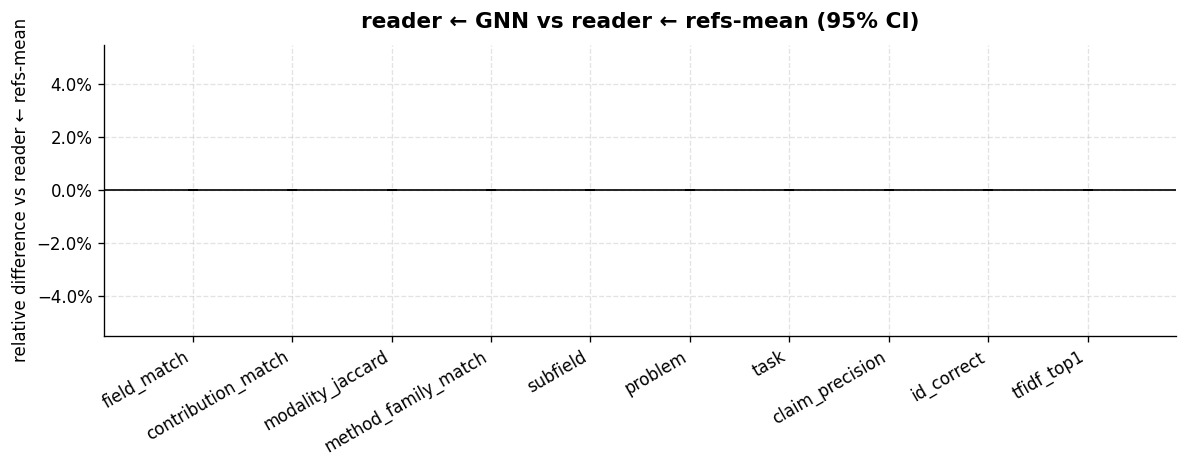

In [16]:
OTHER = '../2026-10-09-14541449_run11-reader-refs-mean/evaluated_result_detailed.csv'
OTHER_NAME = 'reader ← refs-mean'

if os.path.exists(OTHER):
    other = pd.read_csv(OTHER)
    COMPARE = [c for c in NUMERIC + ['tfidf_top1'] if c != 'pair_score']
    for col in COMPARE:
        if col in other.columns:
            other[col] = pd.to_numeric(other[col], errors='coerce')
    other['tfidf_top1'] = (other['tfidf_rank'] == 1).astype(float)
    both = df.merge(other, on='node_id', suffixes=('', '_other'))
    rows = []
    for col in COMPARE:
        d = (both[col] - both[f'{col}_other']).dropna()
        rows.append({'metric': col, ARM: both[col].mean(), OTHER_NAME: both[f'{col}_other'].mean(),
                     'diff': d.mean(), 'SE': d.std() / np.sqrt(len(d)), 'n': len(d)})
    paired = pd.DataFrame(rows).set_index('metric')
    paired['z'] = paired['diff'] / paired['SE']
    display(paired.round(3))

    # Relative difference on the main per-dimension metrics
    MAIN = ['field_match', 'contribution_match', 'modality_jaccard', 'method_family_match',
            'subfield', 'problem', 'task', 'claim_precision', 'id_correct', 'tfidf_top1']
    rel = paired.loc[MAIN, 'diff'] / paired.loc[MAIN, OTHER_NAME]
    err = paired.loc[MAIN, 'SE'] / paired.loc[MAIN, OTHER_NAME]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(MAIN, rel.values, yerr=1.96 * err.values, capsize=3,
           color=['#55A868' if v > 0 else '#C44E52' for v in rel.values], edgecolor='white')
    ax.axhline(0, color='black', linewidth=1)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylabel(f'relative difference vs {OTHER_NAME}')
    ax.set_title(f'{ARM} vs {OTHER_NAME} (95% CI)', fontsize=13, fontweight='bold', pad=10)
    plt.xticks(rotation=30, ha='right')
    fig.tight_layout()
    plt.show()
else:
    print(f'{OTHER} not found yet')